# Five follow-ups to the tag and profit analysis

`notebooks/tag_profit.ipynb` found that the Tag Genome's tags go with a film's return, and that most of it is the
audience leaking in: the scores are built from what viewers tagged and wrote, and they predict a film's vote count.
This notebook does the five things that finding pointed to.

1. Tags measured from the plot instead of the audience.
2. Whether directors and studios return more when they stay in their usual genre mix.
3. Which films are seen and liked but don't earn, and the reverse.
4. Where critics and viewers disagree, and whether the gap goes with the return.
5. Franchise and release month as controls.

It reads the saved outputs of `scripts/reviews/plot_tags.py` and `scripts/reviews/tag_followups.py`. The return
throughout is ln(gross ÷ budget) with ln(budget) and release decade held fixed. Gross over budget isn't profit:
budgets leave out marketing and cinemas keep part of the gross.

In [1]:
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Markdown, display

SRC = Path.cwd().resolve().parent / "analysis" / "tags"
plot = json.loads((SRC / "plot_tags.json").read_text())
fol = json.loads((SRC / "tag_followups.json").read_text())
plot_tags = pd.read_csv(SRC / "plot_tags_tags.csv", keep_default_na=False)
INK, ACCENT, GREY, LIGHT, RED = "#1F2933", "#1F6F8B", "#8A969C", "#D5E3E8", "#B5482F"
plt.rcParams.update({"figure.dpi": 110, "font.size": 9, "axes.spines.top": False, "axes.spines.right": False})

rec, leak, ret, scr = plot["recovery"], plot["leak"], plot["return"], plot["screenplays"]
um, au, cr, ct = fol["usual_mix"], fol["audience"], fol["critics"], fol["controls"]
lab = "IMDb genre labels (all years)"
pe, sf = ret["sets"]["plot embedding"], ret["scored_films"]
display(Markdown(f"""**Short answers.**

1. A plot summary recovers a film's genres well (AUC {rec['genre_auc_mean']['plot_films_after_2014']:.2f} against IMDb's
   labels on films after 2014, which the Tag Genome doesn't cover) and carries little of the audience: it predicts
   votes with R² {leak['r2_votes_from_plot_embedding']:.2f}, against {leak['r2_votes_from_tag_genome_content_tags']:.2f}
   for the Tag Genome's tags. Measured this way, content accounts for {pe['random_folds']:.0%} of the return on
   random folds and {max(pe['trained_before_2005'], 0):.0%} of the return of later films, against
   {sf['Tag Genome content tags']['trained_before_2005']:.0%} for the Tag Genome's tags on the films it covers.
2. Films far from their director's or studio's usual genre mix return less: rho
   {um[lab]['director']['against_adjusted_genre_fixed']['rho']:+.2f} for directors and
   {um[lab]['studio']['against_adjusted_genre_fixed']['rho']:+.2f} for studios, with the film's own genres held fixed.
3. Liking and earning agree only loosely: the IMDb rating goes with the return at rho
   {au['rating_vs_adjusted']['rho']:+.2f}. {au['quadrants']["liked, didn't earn"]:.0%} of films are liked and
   didn't earn, and {au['quadrants']['not liked, earned']:.0%} are the reverse.
4. Critics and viewers disagree by genre in a stable way, and the size of the gap doesn't go with the return
   (rho {cr['metacritic']['gap_vs_adjusted']['rho']:+.2f} with Metacritic, {cr['rotten_tomatoes']['gap_vs_adjusted']['rho']:+.2f}
   with Rotten Tomatoes).
5. Following another film accounts for {ct['with_controls']['by_follows_alone']:.1%} of the variance in the return and
   release month for {ct['release_month']['share_of_variance_in_adjusted']:.1%}. Holding both fixed leaves the tag results
   in place."""))

**Short answers.**

1. A plot summary recovers a film's genres well (AUC 0.88 against IMDb's
   labels on films after 2014, which the Tag Genome doesn't cover) and carries little of the audience: it predicts
   votes with R² 0.12, against 0.77
   for the Tag Genome's tags. Measured this way, content accounts for 6% of the return on
   random folds and 4% of the return of later films, against
   25% for the Tag Genome's tags on the films it covers.
2. Films far from their director's or studio's usual genre mix return less: rho
   -0.05 for directors and
   -0.10 for studios, with the film's own genres held fixed.
3. Liking and earning agree only loosely: the IMDb rating goes with the return at rho
   +0.26. 20% of films are liked and
   didn't earn, and 22% are the reverse.
4. Critics and viewers disagree by genre in a stable way, and the size of the gap doesn't go with the return
   (rho -0.06 with Metacritic, -0.00
   with Rotten Tomatoes).
5. Following another film accounts for 2.4% of the variance in the return and
   release month for 1.6%. Holding both fixed leaves the tag results
   in place.

## 1. Tags from plots

**What we did.** Each film's Wikipedia plot section is embedded with the same sentence model as the screenplays
(`scripts/reviews/plot_embeddings.py`). A ridge regression then predicts all 1,084 Tag Genome scores from that
embedding, trained on the films that have both. Every scored film's tags come from a model that never saw that
film. A plot says what happens in the film. It doesn't say how many people watched it, which is the leak.

In [2]:
print(f"{plot['films_with_plot']:,} of {plot['films_in_graph']:,} films have a plot section; {plot['films_with_plot_and_tag_scores']:,} also have Tag Genome scores")
print(f"plot length: median {plot['plot_words']['median']:.0f} words, 10th to 90th percentile {plot['plot_words']['p10']:.0f} to {plot['plot_words']['p90']:.0f}")
bc = pd.DataFrame(rec["by_class"]).T
bc.columns = ["tags", "median r", "10th percentile r", "tags with r over 0.5"]
print("\nhow well a plot recovers a tag (Pearson r with the Tag Genome score, out of fold):")
display(bc.style.format({"tags": "{:.0f}", "median r": "{:.2f}", "10th percentile r": "{:.2f}", "tags with r over 0.5": "{:.0f}"}))
print("best recovered:", ", ".join(f"{t} {r:.2f}" for t, r in rec["best_tags"][:10]))
print("worst recovered:", ", ".join(f"{t} {r:.2f}" for t, r in rec["worst_tags"][:10]))

12,326 of 12,673 films have a plot section; 6,451 also have Tag Genome scores
plot length: median 611 words, 10th to 90th percentile 360 to 760

how well a plot recovers a tag (Pearson r with the Tag Genome score, out of fold):


,tags,median r,10th percentile r,tags with r over 0.5
content,922,0.43,0.27,238
reception,148,0.42,0.31,25
commercial,14,0.42,0.28,5


best recovered: sports 0.75, action 0.73, fighting 0.70, war 0.69, gunfight 0.69, horror 0.69, science 0.68, space 0.68, relationships 0.68, murder 0.67
worst recovered: firefly 0.03, neo-nazis 0.11, claymation 0.12, aardman 0.13, chicago 0.14, spelling bee 0.14, miyazaki 0.15, monty python 0.16, tarantino 0.16, jay and silent bob 0.16


A plot recovers what a film is about (sports, war, space, murder) and can't recover who made it
("tarantino", "aardman") or a single odd subject. Reception tags are recovered about as well as content tags,
which says that a good part of "funny" or "boring" follows from the kind of film it is.

The check against IMDb's genre labels is the important one, because it can be run on the films after 2014 that the
Tag Genome never scored.

In [3]:
auc = pd.DataFrame(rec["genre_auc"]).T
auc.columns = ["plot, scored films", "Tag Genome, scored films", "plot, films after 2014", "IMDb-labelled films after 2014"]
display(auc.sort_values("plot, films after 2014").style.format({c: "{:.3f}" for c in auc.columns[:3]} | {auc.columns[3]: "{:.0f}"}, na_rep="too few"))
m = rec["genre_auc_mean"]
print(f"mean AUC: plot on scored films {m['plot_scored_films']:.3f}, Tag Genome on the same films {m['tag_genome_scored_films']:.3f}, "
      f"plot on the {rec['films_after_2014']:,} films after 2014 {m['plot_films_after_2014']:.3f}")
t = rec["top_share_genre_in_imdb"]
print(f"largest plot-based genre share is one of the film's IMDb genres: {t['scored_films']:.1%} of scored films, {t['films_after']:.1%} of films after 2014")
print(f"same top genre as the Tag Genome: {rec['top_genre_agrees_with_tag_genome']:.1%}")

,"plot, scored films","Tag Genome, scored films","plot, films after 2014",IMDb-labelled films after 2014
Musical,0.877,0.991,0.740,33
Thriller,0.799,0.813,0.755,775
Drama,0.807,0.838,0.789,2333
Fantasy,0.818,0.850,0.796,281
Comedy,0.828,0.927,0.813,1272
Mystery,0.858,0.881,0.814,544
Family,0.871,0.881,0.837,120
Romance,0.840,0.830,0.872,513
Adventure,0.900,0.906,0.896,726
Biography,0.906,0.945,0.897,392


mean AUC: plot on scored films 0.900, Tag Genome on the same films 0.925, plot on the 4,042 films after 2014 0.881
largest plot-based genre share is one of the film's IMDb genres: 78.1% of scored films, 78.1% of films after 2014
same top genre as the Tag Genome: 43.3%


The plot-based genres are a little weaker than the Tag Genome's and hold up almost unchanged on films from
after 2014. Their top genre matches the Tag Genome's less than half the time, mostly because a predicted score is
smoother, so the largest share often goes to a broad genre such as Drama or Action. Use them for "which genres",
not for "exactly how much".

**The leak check.** How well each set of features predicts ln(IMDb votes), with budget and decade held fixed.

In [4]:
rows = {"Tag Genome content tags (scored films)": leak["r2_votes_from_tag_genome_content_tags"],
        "plot embedding (scored films)": leak["r2_votes_from_plot_embedding_scored_films"],
        "plot embedding (all clean films)": leak["r2_votes_from_plot_embedding"],
        "plot-predicted content tags": leak["r2_votes_from_plot_content_tags"],
        "IMDb genre labels": leak["r2_votes_from_imdb_genre_labels"]}
display(pd.Series(rows, name="R² for votes").to_frame().style.format("{:.3f}"))
print(f"plot length against votes: rho {leak['rho_plot_words_with_votes']:+.3f}; against the return: rho {leak['rho_plot_words_with_adjusted']:+.3f}")

,R² for votes
Tag Genome content tags (scored films),0.772
plot embedding (scored films),0.098
plot embedding (all clean films),0.125
plot-predicted content tags,0.104
IMDb genre labels,0.039


plot length against votes: rho +0.207; against the return: rho +0.079


The plot carries a small part of the audience signal the Tag Genome carries. It isn't zero: better-known
films get longer plot summaries, and some kinds of film do draw bigger audiences.

**The return.** Out-of-sample R² of the adjusted return. "r" is the correlation between predicted and actual
returns on the later films, which shows the direction even when R² is near zero.

In [5]:
rows = {}
for name, v in ret["sets"].items():
    rows[name] = {"features": v["features"], "random folds": v["random_folds"], "highest with outcome shuffled": v["null_max"],
                  "trained before 2005: R²": v["trained_before_2005"], "r": v["r_trained_before_2005"],
                  "trained to 2014, tested after: R²": v["trained_to_2014_tested_after"], "r ": v["r_trained_to_2014_tested_after"],
                  "votes fixed, random folds": v["votes_fixed_random_folds"]}
p = pd.DataFrame(rows).T
display(p.style.format({c: "{:.3f}" for c in p.columns[1:]} | {"features": "{:.0f}"}))
print(f"{ret['films']:,} clean films with a plot; {ret['films_from_2005']:,} from 2005 on; {ret['films_after_2014']:,} after 2014")
same = pd.DataFrame({k: v for k, v in sf.items() if isinstance(v, dict)}).T
same.columns = ["random folds", "trained before 2005: R²", "r", "votes fixed, trained before 2005: R²"]
print(f"\nthe same test on the {sf['films']:,} films that also have Tag Genome scores:")
display(same.style.format("{:.3f}"))

,features,random folds,highest with outcome shuffled,trained before 2005: R²,r,"trained to 2014, tested after: R²",r,"votes fixed, random folds"
plot embedding,384,0.060,-0.005,0.036,0.195,0.054,0.235,0.059
plot-predicted content tags,922,0.059,-0.003,0.040,0.205,0.063,0.254,0.069
IMDb genre labels,22,0.032,0.001,0.025,0.163,0.043,0.220,0.066
plot embedding + IMDb genre labels,406,0.075,-0.007,0.050,0.230,0.072,0.274,0.087


6,399 clean films with a plot; 3,668 from 2005 on; 1,535 after 2014

the same test on the 4,242 films that also have Tag Genome scores:


,random folds,trained before 2005: R²,r,"votes fixed, trained before 2005: R²"
Tag Genome content tags,0.350,0.250,0.521,0.215
plot embedding,0.061,0.041,0.214,0.044
plot-predicted content tags,0.054,0.040,0.210,0.058
IMDb genre labels,0.024,0.010,0.137,0.045


Read the second table first. On the same films and the same split, the Tag Genome's tags account for several
times more of the return than the plot does, and holding votes fixed closes little of the gap. Two things could
make up the difference. The Tag Genome may describe content more finely than a 600-word summary can. Or its scores,
built from reviews and ratings, hold more of the reception than the vote count captures. These data can't separate
the two.

What can be said: content measured from the plot accounts for a few percent of the return, a little more than
IMDb's genre labels, and it carries forward to later films, including the films after 2014. So the range for "what
a film is about" runs from a few percent (plots) to about a quarter (Tag Genome), and only the low end is free of
the audience.

238 content tags are recovered with r over 0.5; family-wise threshold 0.048; largest |rho| of a content tag 0.147
plot-based rho against Tag Genome rho for the same tag, same films: r 0.66, same sign for 66%; median |rho| 0.033 from plots, 0.063 from the Tag Genome


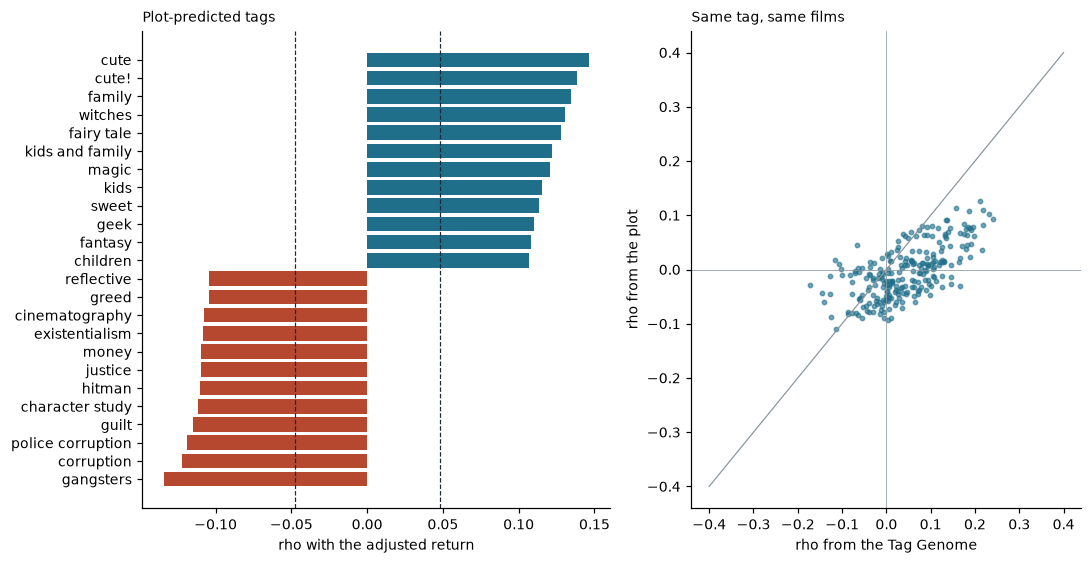

In [6]:
pt = ret["per_tag"]
ag = pt["agreement_with_tag_genome"]
print(f"{pt['content_tags_recovered_r_over_0.5']} content tags are recovered with r over 0.5; family-wise threshold {pt['familywise_95']:.3f}; "
      f"largest |rho| of a content tag {pt['largest_abs_rho_content']:.3f}")
print(f"plot-based rho against Tag Genome rho for the same tag, same films: r {ag['r_between_rhos_recovered_content']:.2f}, "
      f"same sign for {ag['same_sign_recovered_content']:.0%}; median |rho| {ag['median_abs_rho_plot']:.3f} from plots, {ag['median_abs_rho_tag_genome']:.3f} from the Tag Genome")
d = plot_tags[(plot_tags["class"] == "content") & (plot_tags["recovery_r"] > 0.5)].sort_values("rho_adjusted_plot")
d = pd.concat([d.head(12), d.tail(12)])
fig, (a, b) = plt.subplots(1, 2, figsize=(10, 5.2), gridspec_kw={"width_ratios": [1.2, 1]})
a.barh(d["tag"], d["rho_adjusted_plot"], color=[RED if v < 0 else ACCENT for v in d["rho_adjusted_plot"]])
for v in (pt["familywise_95"], -pt["familywise_95"]):
    a.axvline(v, color=INK, ls="--", lw=0.8)
a.set_xlabel("rho with the adjusted return"); a.set_title("Plot-predicted tags", loc="left", fontsize=9)
u = plot_tags[(plot_tags["class"] == "content") & (plot_tags["recovery_r"] > 0.5)]
b.scatter(u["rho_adjusted_tag_genome"], u["rho_adjusted_plot_scored_films"], s=8, color=ACCENT, alpha=0.6)
lim = [-0.4, 0.4]; b.plot(lim, lim, color=GREY, lw=0.8); b.axhline(0, color=GREY, lw=0.5); b.axvline(0, color=GREY, lw=0.5)
b.set_xlabel("rho from the Tag Genome"); b.set_ylabel("rho from the plot"); b.set_title("Same tag, same films", loc="left", fontsize=9)
plt.tight_layout(); plt.show()

The direction survives: family, fairy-tale and children's films above their budget, gangster, corruption
and character-study films below. The sizes are about half of what the Tag Genome showed, and two thirds of the
tags keep their sign. So the earlier picture had roughly the right shape and was too large.

**Screenplays** are the second pre-release source, on the films that have one.

In [7]:
s = scr
print(f"{s['films_with_script_and_tag_scores']:,} films with a screenplay and Tag Genome scores")
print(f"content tags, median r: screenplay {s['recovery_by_class']['content']['median_r']:.2f}, plot on the same films {s['plot_on_the_same_films']['by_class']['content']['median_r']:.2f}; "
      f"the two recover the same tags well and badly (r {s['r_between_per_tag_recovery_of_script_and_plot']:.2f} across tags)")
r = pd.DataFrame({k: v for k, v in s["return"].items() if isinstance(v, dict)}).T
r.columns = ["random folds", "highest with outcome shuffled", "trained before 2005: R²", "r"]
print(f"\nthe return, {s['return']['films']:,} clean films with a screenplay ({s['return']['films_from_2005']:,} from 2005):")
display(r.style.format("{:.3f}"))

1,371 films with a screenplay and Tag Genome scores
content tags, median r: screenplay 0.43, plot on the same films 0.39; the two recover the same tags well and badly (r 0.94 across tags)

the return, 1,628 clean films with a screenplay (886 from 2005):


,random folds,highest with outcome shuffled,trained before 2005: R²,r
screenplay embedding,0.021,0.000,0.015,0.131
plot embedding,0.025,-0.003,0.018,0.142
IMDb genre labels,0.007,0.005,0.010,0.102


A screenplay recovers tags slightly better than a plot summary, and the two agree closely on which tags
are recoverable, so the plot results aren't an oddity of Wikipedia's summaries. On the return a screenplay does no
better than a plot. The screenplay sample is small and tilted to well-known films, so its numbers are rough.

### Any tag, for every year

The table behind all of this, `features/plot_tag_relevance.npy`, has all 1,084 tags for every film with a plot,
including the films after 2014 that the Tag Genome never scored. It comes in the `plot-tags-2026-11-16` bundle, so
this part reads `data/raw` and needs `./setup.sh --data` first.

Only tags a plot recovers well are worth reading this way. The cell below keeps tags with r of at least 0.5 against
the Tag Genome and, for a few of them, lists the films the plot scores highest.

In [8]:
FEAT = Path.cwd().resolve().parent / "data" / "raw" / "features"
if not (FEAT / "plot_tag_relevance.npy").exists():
    print("data/raw/features/plot_tag_relevance.npy is missing: run ./setup.sh --data from the repo root")
else:
    prel = np.load(FEAT / "plot_tag_relevance.npy")
    pids = pd.read_csv(FEAT / "plot_tag_relevance_ids.csv")
    tag_list = pd.read_csv(FEAT / "tag_relevance_tags.csv", keep_default_na=False)["tag"].tolist()
    pfilms = pd.read_csv(FEAT / "plot_genre_shares.csv").set_index("tconst").reindex(pids["tconst"]).reset_index()
    grel = np.load(FEAT / "tag_relevance.npy")
    gids = {t: i for i, t in enumerate(pd.read_csv(FEAT / "tag_relevance_ids.csv")["tconst"])}
    rec = dict(zip(plot_tags["tag"], plot_tags["recovery_r"]))
    good = [t for t in tag_list if rec.get(t, 0) >= 0.5]
    late = (pfilms["y"] > 2014).to_numpy()
    print(f"{prel.shape[0]:,} films x {prel.shape[1]:,} tags; {late.sum():,} films after 2014; {len(good)} tags recovered at r 0.5 or more")

    def top_films(tag, n=10):
        j = tag_list.index(tag)
        order = np.argsort(-prel[:, j])[:n]
        out = pfilms.loc[order, ["primaryTitle", "y", "genres"]].assign(plot_score=prel[order, j].round(3))
        out["Tag Genome score"] = [round(float(grel[gids[t], j]), 3) if t in gids else None for t in pfilms["tconst"][order]]
        return out.reset_index(drop=True)

    for tag in [t for t in ("space", "heist", "vampires", "martial arts", "high school", "zombies") if t in good][:4]:
        d = top_films(tag)
        print(f"\n{tag} (recovered at r {rec[tag]:.2f}); {int((d['y'] > 2014).sum())} of the top 10 are after 2014")
        display(d)

12,326 films x 1,084 tags; 4,042 films after 2014; 268 tags recovered at r 0.5 or more

space (recovered at r 0.68); 4 of the top 10 are after 2014


,primaryTitle,y,genres,plot_score,Tag Genome score
0,Independence Day: Resurgence,2016,"Action,Adventure,Sci-Fi",0.733,NaN
1,The Wandering Earth,2019,"Action,Adventure,Sci-Fi",0.730,NaN
2,Mission to Mars,2000,"Adventure,Sci-Fi,Thriller",0.717,0.992
3,Project Hail Mary,2026,"Adventure,Comedy,Sci-Fi",0.713,NaN
4,Star Trek: The Motion Picture,1979,"Adventure,Mystery,Sci-Fi",0.696,0.996
5,Lost in Space,1998,"Action,Adventure,Sci-Fi",0.690,0.994
6,Star Trek II: The Wrath of Khan,1982,"Action,Adventure,Sci-Fi",0.686,0.994
7,Interstellar,2014,"Adventure,Sci-Fi",0.677,NaN
8,2001: A Space Odyssey,1968,"Adventure,Sci-Fi",0.674,0.968
9,Moonfall,2022,"Action,Adventure,Sci-Fi",0.671,NaN



heist (recovered at r 0.53); 4 of the top 10 are after 2014


,primaryTitle,y,genres,plot_score,Tag Genome score
0,The Heist of the Century,2020,"Action,Biography,Comedy",0.543,NaN
1,King of Thieves,2018,"Biography,Crime,Drama",0.513,NaN
2,Inside Man,2006,"Crime,Drama,Mystery",0.500,0.991
3,The Thomas Crown Affair,1968,"Crime,Drama,Romance",0.498,0.980
4,Empire State,2013,"Crime,Thriller",0.498,NaN
5,Foolproof,2003,"Action,Comedy,Crime",0.487,NaN
6,Flawless,2007,"Crime,Drama,Thriller",0.455,0.983
7,Den of Thieves,2018,"Action,Crime,Drama",0.451,NaN
8,Ocean's Thirteen,2007,"Crime,Thriller",0.449,0.987
9,Thunivu,2023,"Action,Crime,Thriller",0.437,NaN



vampires (recovered at r 0.56); 0 of the top 10 are after 2014


,primaryTitle,y,genres,plot_score,Tag Genome score
0,Dracula Untold,2014,"Action,Drama,Fantasy",0.496,NaN
1,Daybreakers,2009,"Action,Horror,Sci-Fi",0.487,0.999
2,Dracula 2000,2000,"Action,Fantasy,Horror",0.456,0.990
3,Dracula: Dead and Loving It,1995,"Comedy,Fantasy,Horror",0.448,0.639
4,Horror of Dracula,1958,"Drama,Horror",0.442,0.987
5,Dracula: Prince of Darkness,1966,Horror,0.439,0.972
6,Dracula,1931,"Drama,Fantasy,Horror",0.436,0.993
7,The Twilight Saga: New Moon,2009,"Adventure,Drama,Fantasy",0.431,0.999
8,Blade,1998,"Action,Horror,Sci-Fi",0.421,0.998
9,Dracula,1992,"Fantasy,Horror,Romance",0.413,0.982



martial arts (recovered at r 0.51); 6 of the top 10 are after 2014


,primaryTitle,y,genres,plot_score,Tag Genome score
0,Man of Tai Chi,2013,"Action,Drama",0.581,NaN
1,Kung Fu Panda 3,2016,"Action,Adventure,Animation",0.579,NaN
2,The Grandmaster,2013,"Action,Biography,Drama",0.556,NaN
3,Fearless,2006,"Action,Biography,Drama",0.555,0.986
4,Kung Fu Panda 4,2024,"Action,Adventure,Animation",0.544,NaN
5,Mortal Kombat Legends: Scorpion's Revenge,2020,"Action,Adventure,Animation",0.543,NaN
6,Mortal Kombat II,2026,"Action,Adventure,Fantasy",0.535,NaN
7,Street Fighter,2026,Action,0.526,NaN
8,Mortal Kombat,2021,"Action,Adventure,Fantasy",0.520,NaN
9,Seven Swords,2005,"Action,Adventure,Fantasy",0.519,NaN


In [9]:
if (FEAT / "plot_tag_relevance.npy").exists():
    # does the plot rank films like the Tag Genome does, tag by tag, on the films that have both?
    both = np.array([t in gids for t in pfilms["tconst"]])
    pr, gr = prel[both], grel[[gids[t] for t in pfilms["tconst"][both]]]
    k = 20
    overlap = []
    for t in good:
        j = tag_list.index(t)
        a, b = set(np.argsort(-pr[:, j])[:k]), set(np.argsort(-gr[:, j])[:k])
        overlap.append(len(a & b) / k)
    print(f"on the {both.sum():,} films with both scores, the plot's top {k} films for a tag share a median of "
          f"{np.median(overlap):.0%} with the Tag Genome's top {k} (10th to 90th percentile {np.percentile(overlap, 10):.0%} to "
          f"{np.percentile(overlap, 90):.0%}), over the {len(good)} well-recovered tags")
    # how common each tag is among later films, against earlier ones. Predicted scores are pulled towards the middle,
    # so a film counts as strong on a tag when it is in that tag's top 5% over all films, not above a fixed 0.5
    cut = np.percentile(prel, 95, axis=0)
    strong = prel >= cut
    early = ~late & (pfilms["y"] >= 1990).to_numpy()
    ch = pd.DataFrame({"tag": tag_list, "1990-2014": strong[early].mean(axis=0), "after 2014": strong[late].mean(axis=0)})
    ch = ch[ch["tag"].isin(good)].assign(change=lambda d: d["after 2014"] - d["1990-2014"]).sort_values("change")
    print(f"highest plot score of any film, median over tags: {np.median(prel.max(axis=0)):.2f}")
    print("\nshare of films in a tag's top 5%, 1990 to 2014 against after 2014 (5% would mean no change; well-recovered tags):")
    display(pd.concat([ch.head(8), ch.tail(8)]).style.format({"1990-2014": "{:.1%}", "after 2014": "{:.1%}", "change": "{:+.1%}"}).hide(axis="index"))

on the 6,451 films with both scores, the plot's top 20 films for a tag share a median of 15% with the Tag Genome's top 20 (10th to 90th percentile 0% to 35%), over the 268 well-recovered tags


highest plot score of any film, median over tags: 0.45

share of films in a tag's top 5%, 1990 to 2014 against after 2014 (5% would mean no change; well-recovered tags):


tag,1990-2014,after 2014,change
very funny,6.1%,3.1%,-3.1%
comedy,6.2%,3.5%,-2.8%
gangsters,5.9%,3.1%,-2.8%
funny,6.3%,3.6%,-2.7%
buddy movie,5.9%,3.4%,-2.5%
undercover cop,6.0%,3.8%,-2.1%
french,5.2%,3.0%,-2.1%
fun movie,5.8%,3.7%,-2.0%
fight scenes,4.6%,6.7%,+2.1%
plot holes,4.6%,6.8%,+2.2%


The top lists hold films that fit the tag, from before and after 2014 alike. But they are not the Tag
Genome's lists: on films that have both, the two top-20 lists share only a few films. A plot score is a regression
prediction, pulled towards the middle (a plot score rarely passes 0.7, where the Tag Genome gives 0.99), and with a
per-tag r of 0.5 to 0.75 the ordering at the very top is loose. So use plot scores to compare groups of films or to
find candidates for a tag, and the Tag Genome where it exists for one film's exact profile.

The last table compares what plots were about before and after 2014, using each tag's top 5% so the pulled-in scale
doesn't matter. It describes the films in our sample, which over-represents well-known films, and Wikipedia's way
of summarising plots may have changed over time as well as the films.

## 2. The usual genre mix

A film's mix is its genre vector. A director's or studio's usual mix at a film is the mean vector of their
strictly earlier films (at least two), so the film's own outcome can't leak in. The departure is 1 minus the
cosine between the two: 0 is "the same mix as always", 1 is "nothing in common".

The mix is measured two ways. IMDb's genre labels cover every year and were not built from audience data, so they
are the main version. The Tag Genome's genre shares are finer and stop in 2014.

mix measured by,whose,films,median departure,rho with return,"rho, own genres fixed",p,null 95%,"rho, track record also fixed"
"genre shares (Tag Genome, to 2014)",director,2137,0.35,-0.166,-0.127,0.001,0.044,-0.153
"genre shares (Tag Genome, to 2014)",studio,3053,0.44,-0.167,-0.129,0.001,0.036,-0.139
IMDb genre labels (all years),director,3340,0.39,-0.063,-0.051,0.005,0.034,-0.049
IMDb genre labels (all years),studio,4897,0.44,-0.103,-0.101,0.001,0.026,-0.072


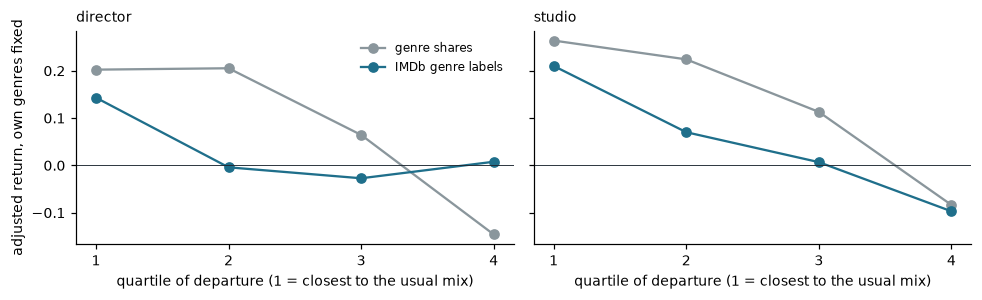

In [10]:
rows = []
for vec, by_role in um.items():
    for role, o in by_role.items():
        tr = o["track_record"]
        rows.append({"mix measured by": vec, "whose": role, "films": o["films"], "median departure": o["median_departure"],
                     "rho with return": o["against_adjusted"]["rho"], "rho, own genres fixed": o["against_adjusted_genre_fixed"]["rho"],
                     "p": o["against_adjusted_genre_fixed"]["p"], "null 95%": o["against_adjusted_genre_fixed"]["null_95"],
                     "rho, track record also fixed": tr["rho_departure_net_of_track"]})
display(pd.DataFrame(rows).style.format({"median departure": "{:.2f}", "rho with return": "{:+.3f}", "rho, own genres fixed": "{:+.3f}",
                                         "p": "{:.3f}", "null 95%": "{:.3f}", "rho, track record also fixed": "{:+.3f}"}).hide(axis="index"))
fig, axes = plt.subplots(1, 2, figsize=(9, 2.8), sharey=True)
for ax, role in zip(axes, ("director", "studio")):
    for vec, col in zip(um, (GREY, ACCENT)):
        q = pd.DataFrame(um[vec][role]["by_quartile"])
        ax.plot(q["quartile"], q["mean_adjusted_genre_fixed"], marker="o", color=col, label=vec.split(" (")[0])
    ax.axhline(0, color=INK, lw=0.6); ax.set_xticks([1, 2, 3, 4]); ax.set_xlabel("quartile of departure (1 = closest to the usual mix)")
    ax.set_title(role, loc="left", fontsize=9)
axes[0].set_ylabel("adjusted return, own genres fixed"); axes[0].legend(frameon=False, fontsize=8)
plt.tight_layout(); plt.show()

Films close to the usual mix return more, for directors and for studios, under both measures. The effect
is small with IMDb's labels and larger with the Tag Genome's shares, which carry the audience leak, so the label
rows are the ones to quote. For directors measured by labels the line isn't a steady slope: the quarter of films
closest to the usual mix stands out and the other three are level. It holds with the film's own genres fixed, so it isn't just "they left for a weaker
genre", and most of it remains with the track record held fixed.

Does a track record count for more when the film stays in the usual mix?

In [11]:
rows = []
for vec, by_role in um.items():
    for role, o in by_role.items():
        tr = o["track_record"]
        rows.append({"mix measured by": vec, "whose": role, "films": tr["films"], "track record when staying": tr["rho_track_when_staying"],
                     "when leaving": tr["rho_track_when_leaving"], "difference": tr["difference"], "p": tr["p"]})
display(pd.DataFrame(rows).style.format({"track record when staying": "{:+.3f}", "when leaving": "{:+.3f}", "difference": "{:+.3f}", "p": "{:.3f}"}).hide(axis="index"))

mix measured by,whose,films,track record when staying,when leaving,difference,p
"genre shares (Tag Genome, to 2014)",director,1996,+0.135,+0.041,+0.094,0.044
"genre shares (Tag Genome, to 2014)",studio,2990,+0.175,+0.120,+0.054,0.151
IMDb genre labels (all years),director,3106,+0.214,+0.115,+0.099,0.008
IMDb genre labels (all years),studio,4782,+0.268,+0.213,+0.055,0.069


The track record predicts the return better for films that stay in the usual mix in all four rows, and the
difference clears chance only for directors measured by IMDb's labels. So there is a lead, mostly for directors: a
director's past returns say more about a film of the kind they usually make.

What this doesn't show: who leaves their usual mix isn't random. A studio short of money, or a director hired for
someone else's project, may both leave the usual mix and return less for other reasons.

## 3. Seen and liked against earned

The project's second question is whether money agrees with whether people liked the film. Here every clean film
from 1975 is used, not only those with tag scores.

In [12]:
for k, name in (("votes_vs_adjusted", "IMDb votes against the return"), ("votes_vs_gross", "IMDb votes against revenue"),
                ("rating_vs_adjusted", "IMDb rating against the return"), ("rating_vs_gross", "IMDb rating against revenue"),
                ("rating_vs_budget", "IMDb rating against budget"), ("rating_vs_votes", "IMDb rating against votes")):
    print(f"{name}: rho {au[k]['rho']:+.3f} over {au[k]['films']:,} films (95% of shuffles under {au[k]['null_95']:.3f})")
print("rating against the return by decade:", {d: round(v, 2) for d, v in au["rating_vs_adjusted_by_decade"].items()})
q = pd.Series(au["quadrants"], name="share of films")
display(q.to_frame().style.format("{:.1%}"))

IMDb votes against the return: rho +0.527 over 6,443 films (95% of shuffles under 0.024)
IMDb votes against revenue: rho +0.698 over 6,443 films (95% of shuffles under 0.024)
IMDb rating against the return: rho +0.261 over 6,443 films (95% of shuffles under 0.024)
IMDb rating against revenue: rho +0.138 over 6,443 films (95% of shuffles under 0.024)
IMDb rating against budget: rho -0.079 over 6,443 films (95% of shuffles under 0.023)
IMDb rating against votes: rho +0.412 over 6,443 films (95% of shuffles under 0.027)
rating against the return by decade: {'1970': 0.11, '1980': 0.21, '1990': 0.29, '2000': 0.28, '2010': 0.26, '2020': 0.24}


,share of films
liked and earned,33.6%
"liked, didn't earn",19.8%
"not liked, earned",22.3%
"not liked, didn't earn",24.4%


How many people saw a film goes with its return far more than how much they liked it. The rating goes with
the return weakly and with revenue more weakly still, because expensive films are rated slightly lower.

"Liked" below means rated above the median of the film's decade, and "earned" means it returned more than its
budget and decade predict. A genre's lift in a group is its share of that group over its share of all films.

,films,liked and earned,"liked, didn't earn","not liked, earned","not liked, didn't earn"
Horror,824,0.57,0.45,1.89,1.23
Sci-Fi,507,0.98,0.52,1.07,1.36
Family,374,0.91,0.53,1.59,0.97
Action,1716,0.94,0.58,1.11,1.31
Adventure,1384,1.11,0.60,1.19,0.99
Fantasy,560,0.84,0.64,1.27,1.28
Animation,364,1.48,0.72,1.08,0.48
Comedy,2514,0.92,0.78,1.20,1.11
Thriller,1080,0.92,0.83,1.17,1.09
Mystery,738,0.81,0.90,1.20,1.16


bold: q below 0.05 (hypergeometric test, Benjamini-Hochberg over all genre and group pairs)


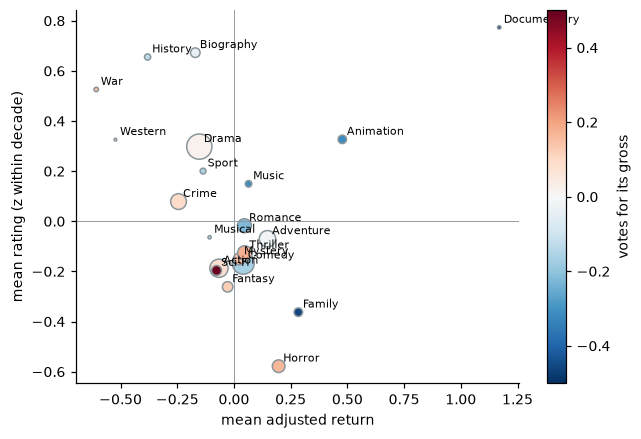

In [13]:
g = pd.DataFrame({k: {"films": v["films"], **v["lift"]} for k, v in au["per_genre"].items()}).T
qv = pd.DataFrame({k: v["lift_q"] for k, v in au["per_genre"].items()}).T
order = g.sort_values("liked, didn't earn").index
display(g.loc[order].style.format({"films": "{:.0f}"} | {c: "{:.2f}" for c in g.columns[1:]})
        .apply(lambda col: ["font-weight: bold" if qv.loc[i, col.name] < 0.05 else "" for i in col.index] if col.name in qv else [""] * len(col), axis=0))
print("bold: q below 0.05 (hypergeometric test, Benjamini-Hochberg over all genre and group pairs)")
att = pd.DataFrame({k: {"rating": v["mean_rating_z"], "return": v["mean_adjusted"], "attention": v["mean_attention"], "films": v["films"]}
                    for k, v in au["per_genre"].items()}).T
fig, ax = plt.subplots(figsize=(6.5, 4.4))
sc = ax.scatter(att["return"], att["rating"], s=att["films"] / 12, c=att["attention"], cmap="RdBu_r", vmin=-0.5, vmax=0.5, edgecolor=GREY)
for name, r in att.iterrows():
    ax.annotate(name, (r["return"], r["rating"]), fontsize=7, xytext=(3, 3), textcoords="offset points")
ax.axhline(0, color=GREY, lw=0.6); ax.axvline(0, color=GREY, lw=0.6)
ax.set_xlabel("mean adjusted return"); ax.set_ylabel("mean rating (z within decade)")
plt.colorbar(sc, label="votes for its gross"); plt.show()

Money and liking part ways by genre. History, Biography and War films are about twice as common among
films that were liked and didn't earn. Horror is the reverse, nearly twice as common among films that earned
without being liked, with Family behind it. Documentary and Animation are over-represented where both are true.

The colour is attention: votes relative to gross. Sci-Fi gets by far the most votes for the money it took, and
Family the fewest. IMDb's voters are not the cinema audience, which is worth remembering whenever votes or ratings
stand in for "people".

## 4. Critics against audience

The gap is the film's critic score minus its IMDb rating, each standardised within release decade. A positive gap
means critics were kinder than viewers. Metacritic is the main score and Rotten Tomatoes the second method.

,films,critics vs IMDb rating,critics vs return,"IMDb rating vs return, same films",gap vs return,p of the gap,gap vs budget,gap vs votes
Metacritic,5103,+0.745,+0.198,+0.250,-0.057,0.001,-0.176,-0.224
Rotten Tomatoes,4550,+0.764,+0.219,+0.230,-0.005,0.745,-0.227,-0.218


the two gaps correlate at 0.81 over 3,743 films; the genre means rank alike (rho 0.96)


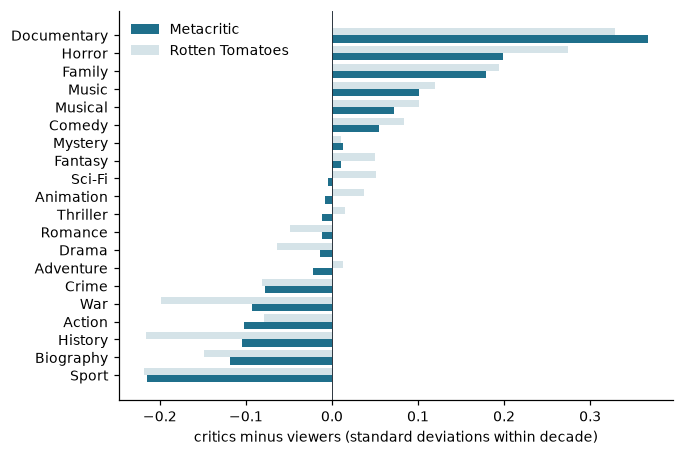

genres whose gap differs from the rest at q below 0.05 (Metacritic): Action, Biography, Comedy, Crime, Family, Horror, Sport


In [14]:
rows = {}
for k, name in (("metacritic", "Metacritic"), ("rotten_tomatoes", "Rotten Tomatoes")):
    c = cr[k]
    rows[name] = {"films": c["films"], "critics vs IMDb rating": c["rho_score_vs_rating"], "critics vs return": c["score_vs_adjusted"]["rho"],
                  "IMDb rating vs return, same films": c["rating_vs_adjusted_same_films"]["rho"], "gap vs return": c["gap_vs_adjusted"]["rho"],
                  "p of the gap": c["gap_vs_adjusted"]["p"], "gap vs budget": c["gap_vs_budget"]["rho"], "gap vs votes": c["gap_vs_votes"]["rho"]}
t = pd.DataFrame(rows).T
display(t.style.format({"films": "{:.0f}", "p of the gap": "{:.3f}"} | {c: "{:+.3f}" for c in t.columns if c not in ("films", "p of the gap")}))
tm = cr["two_methods"]
print(f"the two gaps correlate at {tm['rho_between_gaps']:.2f} over {tm['films']:,} films; the genre means rank alike (rho {tm['rho_per_genre_mean_gaps']:.2f})")
mc, rt = pd.DataFrame(cr["metacritic"]["per_genre"]).T, pd.DataFrame(cr["rotten_tomatoes"]["per_genre"]).T
g = pd.DataFrame({"Metacritic": mc["mean_gap"], "Rotten Tomatoes": rt["mean_gap"]}).dropna().sort_values("Metacritic")
fig, ax = plt.subplots(figsize=(6.5, 4.6))
y = np.arange(len(g))
ax.barh(y - 0.2, g["Metacritic"], 0.4, color=ACCENT, label="Metacritic"); ax.barh(y + 0.2, g["Rotten Tomatoes"], 0.4, color=LIGHT, label="Rotten Tomatoes")
ax.set_yticks(y, g.index); ax.axvline(0, color=INK, lw=0.6); ax.legend(frameon=False)
ax.set_xlabel("critics minus viewers (standard deviations within decade)"); plt.show()
sig = mc[mc["q"] < 0.05].index.tolist()
print("genres whose gap differs from the rest at q below 0.05 (Metacritic):", ", ".join(sig))

Critics rate Horror, Family, Documentary and Comedy above where viewers put them, and Sport, Biography,
History, War, Action and Crime below. Both critic scores give the same order, so it isn't a quirk of one site.

Critics and viewers each go with the return to about the same degree, and the gap between them doesn't. A film
that critics liked more than viewers did, or less, earns no differently for its budget. The gap is larger for cheap
and little-seen films, which is where the two groups are watching different films.

## 5. Franchise and release month

**The franchise flag** comes from Wikidata. It is known to be loose, so here it is checked against two other
signals: the Tag Genome's own sequel tags, and titles that carry a number or "Part".

In [15]:
fr = ct["franchise"]
print(f"{fr['flagged']:.1%} of {fr['films_with_flag']:,} clean films are flagged; {fr['follows_another_film']:.1%} follow another film; "
      f"{fr['numbered_title']:.1%} have a numbered title")
print(f"numbered titles that are flagged: {fr['numbered_titles_flagged']:.1%}; flagged films with a numbered title: {fr['flagged_with_numbered_title']:.1%}; "
      f"films that follow another with a numbered title: {fr['follows_with_numbered_title']:.1%}")
tc = pd.DataFrame(fr["tag_check"]).T
tc.columns = ["AUC for the flag", "AUC for 'follows'", "flagged, among films with the tag at 0.5+", "films with the tag at 0.5+",
              "tag at 0.5+, among flagged", "tag at 0.5+, among films that follow"]
display(tc.style.format({c: "{:.3f}" for c in tc.columns if c != "films with the tag at 0.5+"} | {"films with the tag at 0.5+": "{:.0f}"}))
ma = fr["mean_adjusted"]
print(f"mean adjusted return: flagged {ma['flagged']:+.2f}, not flagged {ma['not_flagged']:+.2f}, follows another film {ma['follows']:+.2f}")
print(f"flag against the return: rho {ma['flag_vs_adjusted']['rho']:+.3f}; 'follows another film' against the return: rho {ma['follows_vs_adjusted']['rho']:+.3f}")

27.1% of 6,443 clean films are flagged; 12.5% follow another film; 5.4% have a numbered title
numbered titles that are flagged: 93.4%; flagged films with a numbered title: 18.8%; films that follow another with a numbered title: 35.1%


,AUC for the flag,AUC for 'follows',"flagged, among films with the tag at 0.5+",films with the tag at 0.5+,"tag at 0.5+, among flagged","tag at 0.5+, among films that follow"
sequel,0.874,0.932,0.988,340,0.290,0.613
sequels,0.861,0.915,0.962,421,0.350,0.636
franchise,0.817,0.886,0.814,650,0.457,0.719
series,0.778,0.837,0.811,312,0.219,0.318


mean adjusted return: flagged +0.71, not flagged -0.26, follows another film +0.57
flag against the return: rho +0.355; 'follows another film' against the return: rho +0.183


The flag is precise and broad. Nearly every film the Tag Genome calls a sequel is flagged, and nearly every
numbered title. But most flagged films are neither: the flag also marks first films that later got a sequel, and
films that belong to a loose series.

That matters for using it as a control. A film gets a sequel because it earned, so the flag partly records the
outcome, and its correlation with the return is twice that of "follows another film". The fact known before
release is that a film follows another one, so that is the control used below. The full flag is the strict variant.

**Release month** is parsed from the Wikipedia infobox.

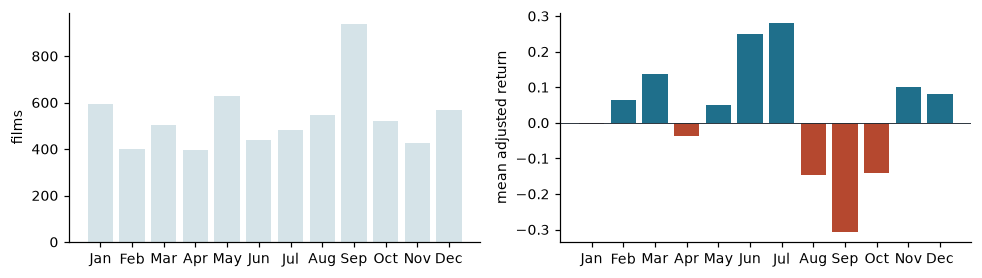

6,440 films with a month. Month accounts for 1.6% of the variance in the adjusted return (95% of shuffles under 0.3%) and 7.8% of the variance in ln(budget)


title,The Social Network,Harry Potter and the Deathly Hallows: Part 1,Batman Begins,Good Will Hunting,Fight Club,Sweeney Todd: The Demon Barber of Fleet Street,Fantastic Four: Rise of the Silver Surfer,About Time,The Last Samurai,The Terminator,Constantine,Hugo,Logan,Toy Story 2,Ant-Man and the Wasp,Fargo,The Lion King,Salt,The Perks of Being a Wallflower,Bohemian Rhapsody,Captain America: Civil War,Poor Things,Catch Me If You Can,Mission: Impossible,John Wick: Chapter 3 - Parabellum
year,2010,2010,2005,1997,1999,2007,2007,2013,2003,1984,2005,2011,2017,1999,2018,1996,1994,2010,2012,2018,2016,2023,2002,1996,2019
month,9,11,5,12,9,12,6,6,11,10,2,10,2,11,6,3,6,7,9,10,4,9,12,5,5


In [16]:
rm = ct["release_month"]
mo = pd.DataFrame(rm["by_month"]).T
mo.index = ["Jan", "Feb", "Mar", "Apr", "May", "Jun", "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"]
fig, (a, b) = plt.subplots(1, 2, figsize=(9, 2.6))
a.bar(mo.index, mo["films"], color=LIGHT); a.set_ylabel("films")
b.bar(mo.index, mo["mean_adjusted"], color=[RED if v < 0 else ACCENT for v in mo["mean_adjusted"]]); b.axhline(0, color=INK, lw=0.6)
b.set_ylabel("mean adjusted return"); plt.tight_layout(); plt.show()
print(f"{rm['films_with_month']:,} films with a month. Month accounts for {rm['share_of_variance_in_adjusted']:.1%} of the variance in the adjusted return "
      f"(95% of shuffles under {rm['share_null_95']:.1%}) and {rm['share_of_variance_in_budget']:.1%} of the variance in ln(budget)")
display(pd.DataFrame(rm["sample_to_check"]).T.style.hide(axis="columns"))

September has almost twice the films of a typical month and the lowest return. That is the autumn
festivals: the infobox lists the first showing, and the parser takes the first date.

The table above is a sample of 25 well-known films. Read from memory of when each film opened in cinemas, and not
checked against a source, 15 of the 25 months are the general release and the other 10 are an earlier premiere or
festival (The Social Network, Batman Begins, Fight Club, About Time, The Last Samurai, Hugo, Logan, Ant-Man and the
Wasp, Captain America: Civil War, Poor Things). So the column is "month of first showing", wrong for the cinema
release in roughly four films in ten, and the September dip is mostly festival films, which are smaller and
artier. A summer and a holiday effect are visible, and small.

**With the controls.** The tag results from `tag_profit.ipynb` again, with "follows another film" and month held
fixed.

share of the variance in the adjusted return: follows another film 2.4%, with month 3.6%; the full flag alone 9.6%
per-tag rho before and after: r 0.94 across all tags; the 40 strongest content tags keep their sign in 100% of cases and 93% of their size
under the strict variant: 100% keep their sign and 80% of their size


,before,after
sequel,+0.258,+0.147
franchise,+0.135,+0.032
sequels,+0.203,+0.097
series,+0.171,+0.080
trilogy,+0.197,+0.134


Tag Genome content tags, R² for the return:


,random folds,trained before 2005
before,0.348,0.251
after,0.321,0.217


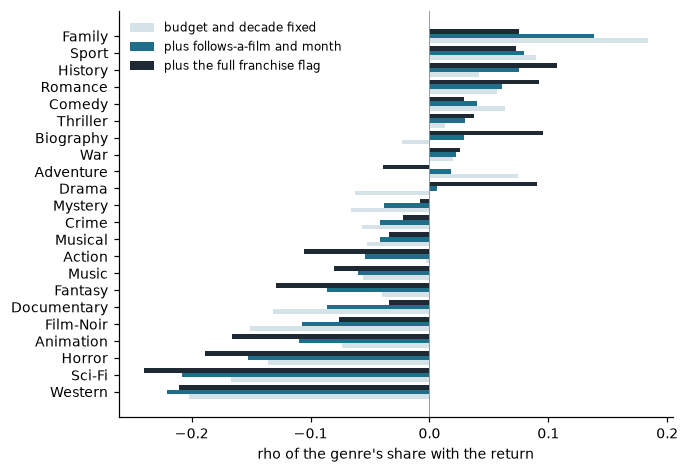

In [17]:
wc = ct["with_controls"]
print(f"share of the variance in the adjusted return: follows another film {wc['by_follows_alone']:.1%}, with month {wc['variance_of_adjusted_explained_by_follows_and_month']:.1%}; "
      f"the full flag alone {wc['by_full_flag_alone']:.1%}")
tg = wc["tags"]
print(f"per-tag rho before and after: r {tg['rho_between_before_and_after']:.2f} across all tags; the 40 strongest content tags keep their sign in "
      f"{tg['top_40_content_same_sign']:.0%} of cases and {tg['top_40_content_mean_shrink']:.0%} of their size")
print(f"under the strict variant: {tg['strict_full_flag']['top_40_content_same_sign']:.0%} keep their sign and {tg['strict_full_flag']['top_40_content_mean_shrink']:.0%} of their size")
display(pd.DataFrame(tg["commercial"]).T.style.format("{:+.3f}"))
r2 = pd.DataFrame(wc["content_tags_r2"]).T
r2.columns = ["random folds", "trained before 2005"]
print("Tag Genome content tags, R² for the return:"); display(r2.style.format("{:.3f}"))
gsh = pd.DataFrame(wc["genre_shares"]).T.sort_values("after")
fig, ax = plt.subplots(figsize=(6.5, 4.8))
y = np.arange(len(gsh))
ax.barh(y - 0.27, gsh["before"], 0.27, color=LIGHT, label="budget and decade fixed")
ax.barh(y, gsh["after"], 0.27, color=ACCENT, label="plus follows-a-film and month")
ax.barh(y + 0.27, gsh["strict"], 0.27, color=INK, label="plus the full franchise flag")
ax.set_yticks(y, gsh.index); ax.axvline(0, color=GREY, lw=0.6); ax.set_xlabel("rho of the genre's share with the return"); ax.legend(frameon=False, fontsize=8)
plt.show()

The controls do what they should: the sequel and franchise tags lose a large part of their correlation with
the return, and nearly all of it under the strict variant. The content tags keep their signs and most of their
size, so the earlier findings weren't sequels in disguise.

Genre shares move in a consistent way. Action, Adventure, Animation, Fantasy and Sci-Fi go down, because much of
their return comes from sequels, and Drama, Biography and History go up.

## What to take from this

- **For the paper's first question**, what a film is about, measured without its audience, accounts for a few
  percent of its return, and that small part does hold on later films. The Tag Genome's much larger figure is an
  upper bound. The plot-based tags are the version to use if tags go into a model, and they exist for every year.
- **The usual-mix result is new and small.** It is leak-free by construction and survives its controls. It is an
  association, and worth a paragraph next to the network results.
- **For the second question**, liking and earning agree weakly, and the disagreement has a clear shape by genre.
  This part needs no tag scores and uses the whole clean sample.
- **Critics against viewers** is a stable description of genres and tells us nothing about money.
- **Use "follows another film" as the franchise control**, and treat release month as the month of first showing
  until the parser picks the general release.
- **Limits that apply throughout**: gross over budget isn't profit, the clean flags are the ones stored in the
  graph bundle, a plot summary is written after release, and every correlation here is over films that reported
  both a budget and a gross.